In [1]:
%cd ..

/Users/maxschmaltz/Documents/DieKonstraintsPrivat/comp_modeling


In [29]:
import os
import numpy as np
import matplotlib.pyplot as plt
from itertools import product
import json

from data_utils.load_datasets import load_tsv_generic

In [3]:
outdir = "out"

In [4]:
with open("out/acceptable_linkers.json", encoding="utf-8") as i:
    acceptable_linkers_all = json.load(i)

with open("out/unacceptable_linkers.json", encoding="utf-8") as i:
    unacceptable_linkers_all = json.load(i)

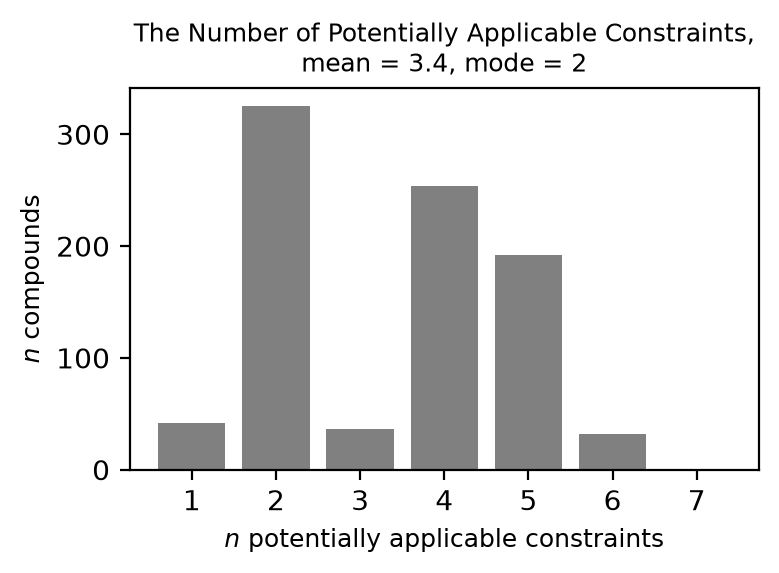

In [42]:
n_constr = [
    sum([len(c_ids) for c_ids in constrs.values()])
    for constrs in acceptable_linkers_all.values()
]

uc = np.unique_counts(n_constr)
x = uc.values
y = uc.counts

mean = np.mean(n_constr).round(1)
mode = x[y.argmax()]

plt.figure(figsize=(4, 3))
plt.bar(x, y, color="grey")
plt.xlabel(r"$n$ potentially applicable constraints", fontsize=9)
plt.ylabel(r"$n$ compounds", fontsize=9)
plt.title(
    "The Number of Potentially Applicable Constraints,\n"
    f"mean = {mean}, mode = {mode}",
    fontsize=9
)
plt.xticks(x)

plt.tight_layout()
plt.savefig("out/n_constrs.png", dpi="figure")
plt.show()

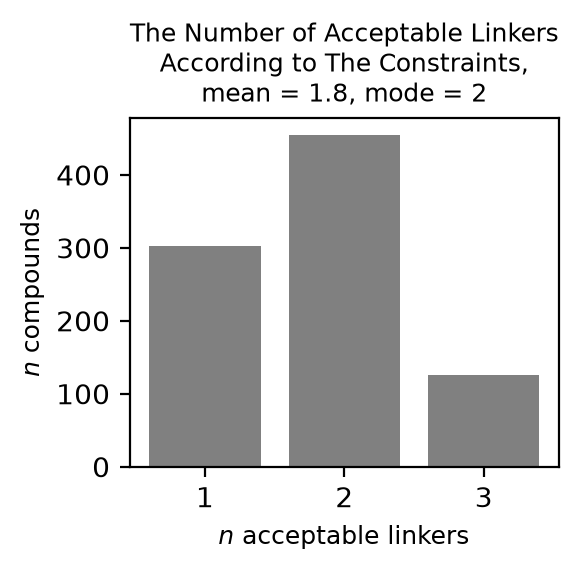

In [40]:
n_accept_linkers = [
    len(accept_linkers)
    for accept_linkers in acceptable_linkers_all.values()
]

uc = np.unique_counts(n_accept_linkers)
x = uc.values
y = uc.counts

mean = np.mean(n_accept_linkers).round(1)
mode = x[y.argmax()]

plt.figure(figsize=(3, 3))
plt.bar(x, y, color="grey")
plt.xlabel(r"$n$ acceptable linkers", fontsize=9)
plt.ylabel(r"$n$ compounds", fontsize=9)
plt.title(
    "The Number of Acceptable Linkers\nAccording to The Constraints,\n"
    f"mean = {mean}, mode = {mode}",
    fontsize=9
)
plt.xticks(x)

plt.tight_layout()
plt.savefig("out/n_acceptable_linkers.png", dpi="figure")
plt.show()

In [49]:
(np.array(n_constr) / np.array(n_accept_linkers)).mean().round(1).item()

1.9

In [ ]:
# warmth plot of types

In [4]:
# from main.py
methods = ["albright-hayes", "yang-cond", "yang-cvg"]
s = lambda x: "+" if x else "-"
keys = [
    f"{s(count_def)}count_def|{s(coop)}coop|{s(l2p)}l2p"
    for count_def, coop, l2p in product([True, False], repeat=3)
]

In [4]:
metrics_summary = load_tsv_generic("out/metrics_summary.tsv")
metrics_summary

,acc,f1
yang-cvg,0.715,0.446
yang-cond,0.713,0.397
albright-hayes,0.667,0.230
rand,0.375,0.128
zero,0.570,0.104


### Albright & Hayes 2002

* The three first best results include the 

In [5]:
method_dir = os.path.join(outdir, "albright-hayes")

In [6]:
# * Three worst results are with -l2p
# * Cooperation does not improve the scores
# * The low metrics are caused by vistually absent
# possibility to produce pluralic linkers due to
# the low regularity of the semantic constraints
metric_summary_ah02 = load_tsv_generic(os.path.join(method_dir, "metrics_summary.tsv"))
metric_summary_ah02

,acc,f1,is_best_key
+count_def|+coop|+l2p,0.667,0.230,True
+count_def|+coop|-l2p,0.667,0.230,False
+count_def|-coop|+l2p,0.667,0.230,False
-count_def|+coop|+l2p,0.667,0.230,False
-count_def|-coop|+l2p,0.667,0.230,False
-count_def|+coop|-l2p,0.667,0.223,False
+count_def|-coop|-l2p,0.660,0.221,False
-count_def|-coop|-l2p,0.660,0.221,False


In [7]:
ldistr_comparison = load_tsv_generic(os.path.join(method_dir, "ldistr_comparison.tsv"))
f1_acc_df = load_tsv_generic(os.path.join(method_dir, "f1_acc_df.tsv"))
cnf_matrix = load_tsv_generic(os.path.join(method_dir, "confusion_matrix.tsv"))

AH02 overproduces a zero linker and underproduces _-en-_ and _-"er-_. All the other linkers are never produced (except for _-s-_ which is produced a negligible number of times).

In [8]:
ldistr_comparison

,reference,ours
_,0.570,0.882
_+en_,0.186,0.090
_+=er_,0.160,0.027
_+e_,0.048,0.000
_+=e_,0.015,0.000
_+s_,0.015,0.001
_+=_,0.007,0.000


This consequently leads to a zero accuracy and F1 score over the four non-produced linkers, and a low recall (hence, F1 score) over the two underproduced linkers. While having a great recall for a zero linker, AH02 is not very precise over it. Overall, the low F1 score is explained by the underrepresentedness of most of the linkers and overfavoring the zero.

In [9]:
f1_acc_df

,acc,f1,N,prec,recall
avg,0.667,0.230,882.0,0.327,0.224
_,0.982,0.771,503.0,0.635,0.982
_+en_,0.476,0.642,164.0,0.987,0.476
_+=er_,0.113,0.194,141.0,0.667,0.113
_+e_,0.000,0.000,42.0,0.000,0.000
_+=e_,0.000,0.000,13.0,0.000,0.000
_+s_,0.000,0.000,13.0,0.000,0.000
_+=_,0.000,0.000,6.0,0.000,0.000


The overproduction of zero originates from the four non-produced linkers: they were all false predicted as zero.

In [10]:
cnf_matrix

,_,_+en_,_+=er_,_+e_,_+=e_,_+s_,_+=_
_,0.982,0.002,0.016,0.0,0.0,0.000,0.0
_+en_,0.518,0.476,0.000,0.0,0.0,0.006,0.0
_+=er_,0.887,0.000,0.113,0.0,0.0,0.000,0.0
_+e_,1.000,0.000,0.000,0.0,0.0,0.000,0.0
_+=e_,1.000,0.000,0.000,0.0,0.0,0.000,0.0
_+s_,1.000,0.000,0.000,0.0,0.0,0.000,0.0
_+=_,1.000,0.000,0.000,0.0,0.0,0.000,0.0


Correspondingly, the constraint(s) for the zero linker must always win the ones for _"0_, _-s-_, _-"e_, and _-e_. Let's investigate the constraint conflicts and their resolution under AH02 to understand why this is the case.

### Short Demonstration of `CompXConstraints`

##### 'Kinderwagen'

In [4]:
comp_gecodb = "kind_+er_wagen"
appl_row = appl_ind.loc[comp_gecodb]
cxc = CompXConstraints(appl_row)
cxc.true

'_+=er_'

In [5]:
cxc.acceptable_linkers

defaultdict(list,
            {'_': ['def-0',
              'p2l:decl_cl:pl:#er-0/er|def-0/er',
              'p2l:decl_cl:pl:#er-0/er|!pl_interpr-0'],
             '_+=er_': ['p2l:decl_cl:pl:#er-0/er|def-0/er',
              'p2l:decl_cl:pl:#er-0/er|anim-er']})

In [6]:
cxc.unacceptable_linkers

defaultdict(list,
            {'_+s_': ['l2p:s|tend_cmpx_morph', 'l2p:s|tend_cmpx_phon'],
             '_+en_': ['l2p:en|par'],
             '_+e_': ['l2p:e|par'],
             '_+=e_': ['l2p:e_uml'],
             '_+=_': ['l2p:0_uml']})

In [7]:
cxc.predict(
    method="albright_hayes",
    count_def_constr=False,
    constr_cooperation=False,
    restrict_with_l2p=False
)

cxc.gen_constr_df

,linker,condition,spec_score,cvg,reg,confidence
c_id,,,,,,
p2l:decl_cl:pl:#er-0/er|!pl_interpr-0,_,[PL:er] & [sem:!PL],25.2,0.171,0.622,0.6220
p2l:decl_cl:pl:#er-0/er|anim-er,_+=er_,[PL:er] & [[sem:anim] | [sem:pers]],28.0,0.003,0.501,0.5010
p2l:decl_cl:pl:#er-0/er|def-0/er,_,[PL:er],14.0,0.021,0.815,0.4075
p2l:decl_cl:pl:#er-0/er|def-0/er,_+=er_,[PL:er],14.0,0.021,0.815,0.4075


In [8]:
cxc.linker_scoreboard

,confidence,cvg,c_id
linker,,,
_,0.622,0.171,p2l:decl_cl:pl:#er-0/er|!pl_interpr-0
_+=er_,0.501,0.003,p2l:decl_cl:pl:#er-0/er|anim-er


In [9]:
cxc.y_pred

'_'

In [10]:
cxc.predict(
    method="albright_hayes",
    count_def_constr=True,
    constr_cooperation=True,
    restrict_with_l2p=False
)
 
cxc.linker_scoreboard

,confidence,cvg,c_id
linker,,,
_,1.0295,0.192,"p2l:decl_cl:pl:#er-0/er|def-0/er, p2l:decl_cl:..."
_+=er_,0.9085,0.024,"p2l:decl_cl:pl:#er-0/er|def-0/er, p2l:decl_cl:..."


##### 'Geschenkeliste'

In [11]:
comp_gecodb = "geschenk_+e_liste"
appl_row = appl_ind.loc[comp_gecodb]
cxc = CompXConstraints(appl_row)
cxc.true

'_+e_'

In [12]:
cxc.predict(
    method="albright_hayes",
    count_def_constr=True,
    constr_cooperation=False,
    restrict_with_l2p=True
)

cxc.restr_constr_df

,linker,condition,spec_score,cvg,reg,confidence
c_id,,,,,,
l2p:er|par,_+=er_,[PL:er],14.0,0.009,1.000,1.000
l2p:e_uml,_+=e_,[PL:ue],14.0,0.003,1.000,1.000
l2p:0_uml,_+=_,[PL:uo],14.0,0.001,1.000,1.000
l2p:en|par,_+en_,[PL:en],14.0,0.152,0.985,0.985
l2p:es|mono_syl,_+es_,[nsyl:mono] | [[nsyl:mono] & [drv:PRX]],20.4,0.010,0.972,0.972
l2p:er|smpx,_+=er_,[drv:smpx],14.0,0.009,0.903,0.903
l2p:e|smpx,_+e_,[drv:smpx],14.0,0.009,0.806,0.806


In [13]:
cxc.linker_scoreboard

,confidence,cvg,c_id,removed_by
linker,,,,
_,0.754,0.162,p2l:decl_cl:pl:#e-0|def-0,
_+s_,0.649,0.159,p2l:drv:prx_deverb-s,
_+e_,0.544,0.079,p2l:decl_cl:pl:#e-0|pl_interpr-e,l2p:e|smpx


In [14]:
cxc.predict(
    method="albright_hayes",
    count_def_constr=False,
    constr_cooperation=True,
    restrict_with_l2p=True
)

cxc.linker_scoreboard

,confidence,cvg,c_id,removed_by
linker,,,,
_,0.754,0.162,p2l:decl_cl:pl:#e-0|def-0,
_+s_,0.649,0.159,p2l:drv:prx_deverb-s,
_+e_,0.544,0.079,p2l:decl_cl:pl:#e-0|pl_interpr-e,l2p:e|smpx


In [15]:
cxc.predict(
    method="yang-cond",
    count_def_constr=True,
    constr_cooperation=False,
    restrict_with_l2p=True
)

cxc.linker_scoreboard

,confidence,cvg,c_id,removed_by
linker,,,,
_+e_,26.8,0.079,p2l:decl_cl:pl:#e-0|pl_interpr-e,
_,14.0,0.162,p2l:decl_cl:pl:#e-0|def-0,
_+s_,12.7,0.159,p2l:drv:prx_deverb-s,


In [16]:
cxc.predict(
    method="yang-cvg",
    count_def_constr=True,
    constr_cooperation=False,
    restrict_with_l2p=True
)

cxc.linker_scoreboard

,confidence,reg,c_id,removed_by
linker,,,,
_+e_,0.079,0.544,p2l:decl_cl:pl:#e-0|pl_interpr-e,
_+s_,0.159,0.649,p2l:drv:prx_deverb-s,
_,0.162,0.754,p2l:decl_cl:pl:#e-0|def-0,


### Prerequisites

In [38]:
ldistr_comparison, accuracies_df, f1_df, cnf_matrix = ah02_metrics["+count_def|+coop|+l2p"]

In [39]:
ldistr_comparison

,reference,ours
_,0.570,0.882
_+en_,0.186,0.090
_+=er_,0.160,0.027
_+e_,0.048,0.000
_+=e_,0.015,0.000
_+s_,0.015,0.001
_+=_,0.007,0.000


In [40]:
cnf_matrix

,_,_+en_,_+=er_,_+e_,_+=e_,_+s_,_+=_
_,0.982,0.002,0.016,0.0,0.0,0.000,0.0
_+en_,0.518,0.476,0.000,0.0,0.0,0.006,0.0
_+=er_,0.887,0.000,0.113,0.0,0.0,0.000,0.0
_+e_,1.000,0.000,0.000,0.0,0.0,0.000,0.0
_+=e_,1.000,0.000,0.000,0.0,0.0,0.000,0.0
_+s_,1.000,0.000,0.000,0.0,0.0,0.000,0.0
_+=_,1.000,0.000,0.000,0.0,0.0,0.000,0.0


In [49]:
for (key_1, preds_1), (key_2, preds_2) in pairwise(Y_pred_ah02.items()):
    print(key_1, "\t", key_2)
    print(round(accuracy_score(preds_1, preds_2), 3))
    print()

+count_def|+coop|+l2p 	 +count_def|+coop|-l2p
1.0

+count_def|+coop|-l2p 	 +count_def|-coop|+l2p
1.0

+count_def|-coop|+l2p 	 +count_def|-coop|-l2p
0.965

+count_def|-coop|-l2p 	 -count_def|+coop|+l2p
0.965

-count_def|+coop|+l2p 	 -count_def|+coop|-l2p
0.972

-count_def|+coop|-l2p 	 -count_def|-coop|+l2p
0.972

-count_def|-coop|+l2p 	 -count_def|-coop|-l2p
0.965



In [50]:
Y_pred_y16_cond = {}
y16_cond_metrics = {}
s = lambda x: "+" if x else "-"
for count_def, coop, l2p in product([True, False], repeat=3):
    key = (
        f"{s(count_def)}count_def|"
        f"{s(coop)}coop|"
        f"{s(l2p)}l2p"
    )
    Y_pred_y16_cond[key] = [
        cxc.predict(
            method="yang-cond",
            count_def_constr=count_def,
            constr_cooperation=coop,
            restrict_with_l2p=l2p
        )
        for cxc in tqdm(cXc)
    ]
    y16_cond_metrics[key] = calculate_metrics(Y_pred_y16_cond[key])

  0%|          | 0/882 [00:00<?, ?it/s]

  0%|          | 0/882 [00:00<?, ?it/s]

  0%|          | 0/882 [00:00<?, ?it/s]

  0%|          | 0/882 [00:00<?, ?it/s]

  0%|          | 0/882 [00:00<?, ?it/s]

  0%|          | 0/882 [00:00<?, ?it/s]

  0%|          | 0/882 [00:00<?, ?it/s]

  0%|          | 0/882 [00:00<?, ?it/s]

In [ ]:
# * All the results are identical
# * L2P cannot restrict anything because their
# conditions are always quite general
metrics_y16_cond_df = pd.DataFrame({
    key: {
        "acc": metrics[1].loc["overall"],
        "acc_balanced": metrics[1].loc["balanced"],
        "f1_avg": metrics[2].loc["avg", "f1"]
    }
    for key, metrics in y16_cond_metrics.items()
}).T.sort_values(by=["f1_avg", "acc_balanced", "acc"], ascending=False)

metrics_y16_cond_df

,acc,acc_balanced,f1_avg
+count_def|+coop|+l2p,0.713,0.361,0.397
+count_def|+coop|-l2p,0.713,0.361,0.397
+count_def|-coop|+l2p,0.713,0.361,0.397
+count_def|-coop|-l2p,0.713,0.361,0.397
-count_def|+coop|+l2p,0.713,0.361,0.397
-count_def|+coop|-l2p,0.713,0.361,0.397
-count_def|-coop|+l2p,0.713,0.361,0.397
-count_def|-coop|-l2p,0.713,0.361,0.397


In [52]:
for (key_1, preds_1), (key_2, preds_2) in pairwise(Y_pred_y16_cond.items()):
    print(key_1, "\t", key_2)
    print(round(accuracy_score(preds_1, preds_2), 3))
    print()

+count_def|+coop|+l2p 	 +count_def|+coop|-l2p
1.0

+count_def|+coop|-l2p 	 +count_def|-coop|+l2p
0.999

+count_def|-coop|+l2p 	 +count_def|-coop|-l2p
1.0

+count_def|-coop|-l2p 	 -count_def|+coop|+l2p
0.999

-count_def|+coop|+l2p 	 -count_def|+coop|-l2p
1.0

-count_def|+coop|-l2p 	 -count_def|-coop|+l2p
0.999

-count_def|-coop|+l2p 	 -count_def|-coop|-l2p
1.0



In [53]:
ldistr_comparison, accuracies_df, f1_df, cnf_matrix = y16_cond_metrics["+count_def|+coop|+l2p"]

In [54]:
ldistr_comparison

,reference,ours
_,0.570,0.748
_+en_,0.186,0.125
_+=er_,0.160,0.101
_+e_,0.048,0.010
_+=e_,0.015,0.007
_+s_,0.015,0.001
_+=_,0.007,0.008


In [55]:
f1_df

,prec,recall,f1,N
avg,0.502,0.361,0.397,126.0
_,0.717,0.940,0.813,503.0
_+en_,0.709,0.476,0.569,164.0
_+=er_,0.775,0.489,0.600,141.0
_+e_,0.333,0.071,0.118,42.0
_+=e_,0.833,0.385,0.526,13.0
_+s_,0.000,0.000,0.000,13.0
_+=_,0.143,0.167,0.154,6.0


In [56]:
cnf_matrix

,_,_+en_,_+=er_,_+e_,_+=e_,_+s_,_+=_
_,0.940,0.014,0.020,0.012,0.002,0.000,0.012
_+en_,0.518,0.476,0.000,0.000,0.000,0.006,0.000
_+=er_,0.511,0.000,0.489,0.000,0.000,0.000,0.000
_+e_,0.381,0.548,0.000,0.071,0.000,0.000,0.000
_+=e_,0.615,0.000,0.000,0.000,0.385,0.000,0.000
_+s_,0.077,0.154,0.769,0.000,0.000,0.000,0.000
_+=_,0.833,0.000,0.000,0.000,0.000,0.000,0.167


In [65]:
Y_pred_y16_cvg = {}
y16_cvg_metrics = {}
s = lambda x: "+" if x else "-"
for count_def, coop, l2p in product([True, False], repeat=3):
    key = (
        f"{s(count_def)}count_def|"
        f"{s(coop)}coop|"
        f"{s(l2p)}l2p"
    )
    Y_pred_y16_cvg[key] = [
        cxc.predict(
            method="yang-cvg",
            count_def_constr=count_def,
            constr_cooperation=coop,
            restrict_with_l2p=l2p
        )
        for cxc in tqdm(cXc)
    ]
    y16_cvg_metrics[key] = calculate_metrics(Y_pred_y16_cvg[key])

  0%|          | 0/882 [00:00<?, ?it/s]

  0%|          | 0/882 [00:00<?, ?it/s]

  0%|          | 0/882 [00:00<?, ?it/s]

  0%|          | 0/882 [00:00<?, ?it/s]

  0%|          | 0/882 [00:00<?, ?it/s]

  0%|          | 0/882 [00:00<?, ?it/s]

  0%|          | 0/882 [00:00<?, ?it/s]

  0%|          | 0/882 [00:00<?, ?it/s]

In [ ]:
# * All four runs with -L2P have the worst results:
# combined with a similar result from AH02, we conclude
# that L2P do play a role
# * Removing cooperation produces better results:
# combined with a similar result from AH02, we conclude
# that compounding constraints do not cooperate
# * On the other hand, relying on cvg only produces too many
# "rare" linkers where they shouldn't be
metrics_y16_cvg_df = pd.DataFrame({
    key: {
        "acc": metrics[1].loc["overall"],
        "acc_balanced": metrics[1].loc["balanced"],
        "f1_avg": metrics[2].loc["avg", "f1"]
    }
    for key, metrics in y16_cvg_metrics.items()
}).T.sort_values(by=["f1_avg", "acc_balanced", "acc"], ascending=False)

metrics_y16_cvg_df

,acc,acc_balanced,f1_avg
+count_def|-coop|+l2p,0.715,0.395,0.446
-count_def|-coop|+l2p,0.715,0.395,0.446
+count_def|+coop|+l2p,0.590,0.421,0.433
-count_def|+coop|+l2p,0.590,0.421,0.433
+count_def|-coop|-l2p,0.689,0.316,0.357
-count_def|-coop|-l2p,0.689,0.316,0.357
+count_def|+coop|-l2p,0.563,0.343,0.343
-count_def|+coop|-l2p,0.563,0.343,0.343


In [67]:
for (key_1, preds_1), (key_2, preds_2) in pairwise(Y_pred_y16_cvg.items()):
    print(key_1, "\t", key_2)
    print(round(accuracy_score(preds_1, preds_2), 3))
    print()

+count_def|+coop|+l2p 	 +count_def|+coop|-l2p
0.965

+count_def|+coop|-l2p 	 +count_def|-coop|+l2p
0.618

+count_def|-coop|+l2p 	 +count_def|-coop|-l2p
0.965

+count_def|-coop|-l2p 	 -count_def|+coop|+l2p
0.618

-count_def|+coop|+l2p 	 -count_def|+coop|-l2p
0.965

-count_def|+coop|-l2p 	 -count_def|-coop|+l2p
0.618

-count_def|-coop|+l2p 	 -count_def|-coop|-l2p
0.965



In [68]:
ldistr_comparison, accuracies_df, f1_df, cnf_matrix = y16_cvg_metrics["+count_def|+coop|+l2p"]

In [69]:
ldistr_comparison

,reference,ours
_,0.570,0.460
_+en_,0.186,0.104
_+=er_,0.160,0.370
_+e_,0.048,0.039
_+=e_,0.015,0.007
_+s_,0.015,0.020
_+=_,0.007,0.000


In [70]:
f1_df

,prec,recall,f1,N
avg,0.518,0.421,0.433,126.0
_,0.692,0.559,0.618,503.0
_+en_,0.967,0.543,0.695,164.0
_+=er_,0.365,0.844,0.510,141.0
_+e_,0.765,0.619,0.684,42.0
_+=e_,0.833,0.385,0.526,13.0
_+s_,0.000,0.000,0.000,13.0
_+=_,0.000,0.000,0.000,6.0


In [71]:
cnf_matrix

,_,_+en_,_+=er_,_+e_,_+=e_,_+s_,_+=_
_,0.559,0.006,0.392,0.012,0.002,0.030,0.0
_+en_,0.457,0.543,0.000,0.000,0.000,0.000,0.0
_+=er_,0.156,0.000,0.844,0.000,0.000,0.000,0.0
_+e_,0.310,0.000,0.000,0.619,0.000,0.071,0.0
_+=e_,0.615,0.000,0.000,0.000,0.385,0.000,0.0
_+s_,0.077,0.000,0.769,0.154,0.000,0.000,0.0
_+=_,1.000,0.000,0.000,0.000,0.000,0.000,0.0
